pjw 1

In [ ]:
!sudo apt-get install -y fonts-nanum
!sudo fc-cache -fv
!rm ~/.cache/matplotlib -rf

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
fonts-nanum is already the newest version (20200506-1).
0 upgraded, 0 newly installed, 0 to remove and 0 not upgraded.
Font directories:
	/root/.local/share/fonts
	/usr/local/share/fonts
	/usr/share/fonts
	/root/.fonts
	/usr/share/fonts/truetype
	/usr/share/fonts/truetype/humor-sans
	/usr/share/fonts/truetype/liberation
	/usr/share/fonts/truetype/nanum
/root/.local/share/fonts: skipping, no such directory
/usr/local/share/fonts: caching, new cache contents: 0 fonts, 0 dirs
/usr/share/fonts: caching, new cache contents: 0 fonts, 1 dirs
/usr/share/fonts/truetype: caching, new cache contents: 0 fonts, 3 dirs
/usr/share/fonts/truetype/humor-sans: caching, new cache contents: 1 fonts, 0 dirs
/usr/share/fonts/truetype/liberation: caching, new cache contents: 12 fonts, 0 dirs
/usr/share/fonts/truetype/nanum: caching, new cache contents: 12 fonts, 0 dirs
/root/.fonts: skipping, no such directory
/u

pjw 2

In [ ]:
from google.colab import files
import pandas as pd

f = files.upload()
print(list(f.keys()))

Saving RawData2.xlsx to RawData2 (5).xlsx
['RawData2 (5).xlsx']


pjw 3

In [ ]:
df = pd.read_excel('RawData2.xlsx')      # 위에서 출력된 파일 이름으로 맞추기
print(df.shape)
print(df.columns)
print(df.head(3))
print(df.isnull().sum())

(393, 20)
Index(['ID', 'Sport', 'Age [year]', 'Sex', 'Weight [kg.]', 'Height [cm.]',
       'BMI', 'Fat [%]', 'Standing Long Jump [cm.]', 'Grip strength [kg./kg.]',
       'Leg strength  [kg./kg.]', 'Sit-up [times.]', 'Push-up [times.]',
       'Shuttle run [secounds.]', 'Flexibility [cm.]',
       'Run 1000 meters [min.sec]', 'Pull  [times.]',
       'Short Run 50 meters [minutes]', 'Run 12 Minute [meters]', 'Medal'],
      dtype='object')
   ID      Sport  Age [year] Sex  Weight [kg.]  Height [cm.]        BMI  \
0   1  Athletics          18   M          84.4         175.0  27.559184   
1   2  Athletics          18   M          68.8         173.0  22.987738   
2   3  Athletics          15   M          60.1         183.0  17.946191   

     Fat [%]  Standing Long Jump [cm.]  Grip strength [kg./kg.]  \
0  10.921739                     220.0                     56.1   
1  10.921739                     251.0                     52.0   
2  10.921739                     240.0               

pjw 4

In [ ]:
df.columns = ['ID', '종목', '나이', '성별', '체중', '키', 'BMI', '체지방',
              '제자리멀리뛰기', '악력', '하체근력', '윗몸일으키기', '팔굽혀펴기',
              '셔틀런', '유연성', '1000m달리기', '턱걸이', '50m달리기',
              '12분달리기', '메달']

print(df['메달'].value_counts())

df = df.drop(columns=['ID'])
df['성별'] = df['성별'].map({'M': 0, 'F': 1})
df['금메달'] = (df['메달'] == 'Gold').astype(int)
df = df.drop(columns=['메달'])
df = pd.get_dummies(df, columns=['종목'], dtype=int)
print(df.shape, df['금메달'].value_counts().to_dict())

메달
Bronze    179
Gold      110
Silver    104
Name: count, dtype: int64
(393, 28) {0: 283, 1: 110}


pjw 5

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

X = df.drop(columns=['금메달'])
y = df['금메달']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
print(X_train.shape, X_test.shape)

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)

(314, 27) (79, 27)


pjw 6

In [ ]:
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.metrics import precision_score, recall_score, f1_score

cm = confusion_matrix(y_test, y_pred)
acc = accuracy_score(y_test, y_pred)
pre = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
base = (y_test == 0).mean()

print(cm)
print('정확도', round(acc, 2), '정밀도', round(pre, 2))
print('재현율', round(rec, 2), 'F1', round(f1, 2))
print('찍기 정확도', round(base, 2))
print('학습 정확도', round(rf.score(X_train, y_train), 2))

[[57  0]
 [14  8]]
정확도 0.82 정밀도 1.0
재현율 0.36 F1 0.53
찍기 정확도 0.72
학습 정확도 1.0


pjw 7

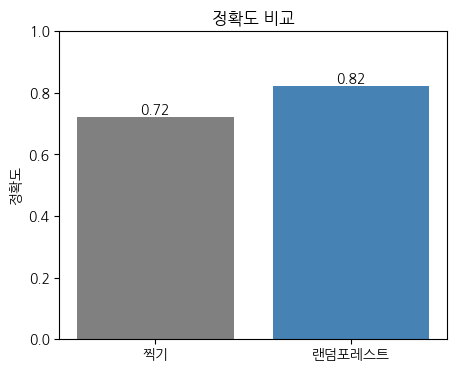

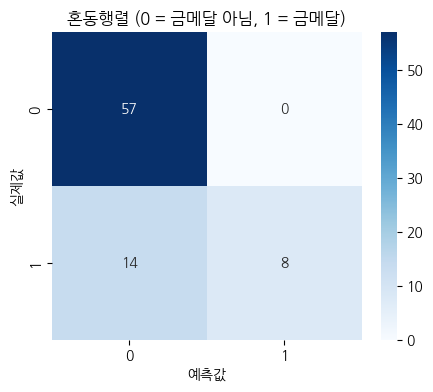

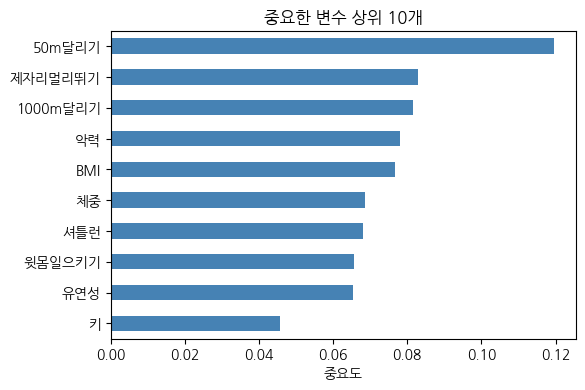

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False

plt.figure(figsize=(5, 4))
plt.bar(['찍기', '랜덤포레스트'], [base, acc], color=['gray', 'steelblue'])
for i, v in enumerate([base, acc]):
    plt.text(i, v + 0.01, round(v, 2), ha='center')
plt.ylim(0, 1)
plt.ylabel('정확도')
plt.title('정확도 비교')
plt.show()

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('예측값')
plt.ylabel('실제값')
plt.title('혼동행렬 (0 = 금메달 아님, 1 = 금메달)')
plt.show()

imp = pd.Series(rf.feature_importances_, index=X.columns)
imp = imp.sort_values(ascending=False).head(10)
plt.figure(figsize=(6, 4))
imp[::-1].plot(kind='barh', color='steelblue')
plt.xlabel('중요도')
plt.title('중요한 변수 상위 10개')
plt.show()